# Predicting recorded warranty cost with Random Forest

**Question:** How accurately can manufacturing and product information predict recorded warranty cost per unit?

The target is recorded dollars, not lifetime cost. The provided warranty table has only positive-cost units. We cannot evaluate no-claim units or a fixed warranty horizon. Prediction is assumed to happen after rework and EOLT are complete.

All models must share the exported units, split assignments, folds, raw features, and metrics. Preprocessing must be learned within each training fold. Test diagnostics are for final reporting only.

## 1. Setup: local Jupyter or Google Colab

Locally, open this notebook from the project root using the project Python environment.
In Colab, put the project folder (including `warranty_model.py`, requirements, and the four Excel inputs) in Google Drive. Set `PROJECT_DIR` below to that folder. The only platform-specific step is mounting Drive.

The full 30-candidate, five-fold search fits 150 forests and can take several minutes. Use two workers by default to limit memory consumption.

In [1]:
from pathlib import Path
import sys
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
PROJECT_DIR = Path('/content/drive/MyDrive/DataFest-2026') if IN_COLAB else Path.cwd()
DATA_DIR = PROJECT_DIR
OUTPUT_DIR = PROJECT_DIR / 'outputs'
N_JOBS = 2
sys.path.insert(0, str(PROJECT_DIR))
assert (PROJECT_DIR / 'warranty_model.py').exists(), 'Set PROJECT_DIR to the project folder.'


In [2]:
# In Colab install the recorded environment when available; otherwise use requirements.txt.
if IN_COLAB:
    import subprocess
    lock = OUTPUT_DIR / 'requirements-lock.txt'
    requirements = lock if lock.exists() else PROJECT_DIR / 'requirements.txt'
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-r', str(requirements)])


In [3]:
import pandas as pd
from IPython.display import display, Image, Markdown
from warranty_model import (
    ID, TARGET, FEATURES, prepare_data, make_splits, partition,
    fit_references, train_model, export_results, save_json,
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


## 2. Audit and prepare one row per unit

Configuration defines the roster. Claim amounts are summed by serial number before joining. Missing claim amounts remain unknown. Conflicting duplicate feature records stop preparation. Facility disagreements and unmatched records appear in the audit. Source hashes and every observed label normalization are exported.

Serial number and all post-shipment warranty/service variables are excluded from the feature list. Formatting normalization does not assume that distinct business terms are synonyms.

In [4]:
data, audit = prepare_data(DATA_DIR)
display(pd.Series({k: audit[k] for k in ['eligible_units', 'target_total', 'zero_cost_units']}))
display(data.head())
display(pd.Series(audit['missing_predictors'], name='Missing predictor values'))
display(audit['facility_discrepancies'])
save_json(audit, OUTPUT_DIR / 'data_audit.json')


eligible_units        3000.0
target_total       7653477.0
zero_cost_units          0.0
dtype: float64

,Serial Number,Product Family,Facility,Controls Revision,Coil Supplier,Rework Shift,Defect Category,Repair Type,Disposition Code,EOLT Shift,Test Station,Failure Mode,Pass After Repair,Retested,Labor Hours,Material Cost,Rework Hours,total_warranty_cost
0,CH2600001,dc100,facility 3,rev a,supplier a,night,controls,sensor rewire,rework completed,night,leak test,sensor miswire,yes,yes,0.7,224.0,1.0,2622.0
1,CH2600002,dc100,facility 3,rev c,supplier c,day,wiring,rewire,rework completed,day,controls test,loose terminal,yes,yes,4.5,454.0,3.3,795.0
2,CH2600003,dc300,facility 2,rev a,supplier a,day,controls,sensor rewire,rework completed,day,functional test,sensor miswire,yes,yes,1.7,414.0,3.1,1395.0
3,CH2600004,dc300,facility 1,rev a,supplier b,night,brazing,leak repair,rework completed,night,electrical test,refrigerant leak,yes,yes,4.0,180.0,3.1,8909.0
4,CH2600005,dc100,facility 1,rev b,supplier c,day,wiring,rewire,use as is,day,leak test,loose terminal,yes,yes,5.8,185.0,0.9,647.0


Product Family       0
Facility             0
Controls Revision    0
Coil Supplier        0
Rework Shift         0
Defect Category      0
Repair Type          0
Disposition Code     0
EOLT Shift           0
Test Station         0
Failure Mode         0
Pass After Repair    0
Retested             0
Labor Hours          0
Material Cost        0
Rework Hours         0
Name: Missing predictor values, dtype: int64

{'rework': [], 'eolt': []}

## 3. Freeze the shared split

Sort units, then reserve 20% for final testing with seed 42. Five shuffled training folds drive tuning. Each exported fold number identifies the validation fold; test rows have fold -1. These random splits assess similar units, not future production. Manufacturing or shipment dates would be needed for chronological validation.

In [5]:
splits = make_splits(data)
train, test, cv = partition(data, splits)
data.to_csv(OUTPUT_DIR / 'modeling_dataset.csv', index=False)
splits.to_csv(OUTPUT_DIR / 'split_assignments.csv', index=False)
display(splits.groupby(['split', 'fold']).size().rename('units'))


split  fold
test   -1      600
train   0      480
        1      480
        2      480
        3      480
        4      480
Name: units, dtype: int64

## 4. Baselines and initial forest

Mean and median constant predictions are sensible reference models. The initial forest uses 500 trees. Numeric medians and missing indicators, plus categorical imputation and one-hot encoding, are fitted inside each fold. Forests need no input scaling.

Below, only training cross-validation scores are displayed. Lower MAE/RMSE is better; higher R² is better.

In [6]:
references, cv_rows = fit_references(data, splits, n_jobs=N_JOBS)
display(pd.DataFrame(cv_rows))


,model,cv_mae_mean,cv_mae_std,cv_rmse_mean,cv_rmse_std,cv_r2_mean,cv_r2_std
0,mean_baseline,2621.640022,79.511217,3124.987229,144.348499,-0.005493,0.003531
1,median_baseline,2091.235417,170.949058,3598.561445,216.879268,-0.331889,0.040473
2,initial_forest,539.498239,19.074417,852.451831,27.469663,0.924829,0.006438


## 5. Tune using training data only

Search 30 seeded combinations of tree count, depth, split size, leaf size, and feature subsampling. Select by mean cross-validation MAE. Every individual forest uses one worker while the search parallelizes candidates/folds. The selected pipeline is automatically refitted on all training units.

In [7]:
search, model = train_model(data, splits, n_jobs=N_JOBS)
display(search.best_params_)
print(f'Selected cross-validation MAE: ${-search.best_score_:,.2f}')


{'model__n_estimators': 500,
 'model__min_samples_split': 2,
 'model__min_samples_leaf': 1,
 'model__max_features': 0.5,
 'model__max_depth': 24}

Selected cross-validation MAE: $533.54


## 6. Final test evaluation and saved artifacts

Evaluate once after model selection. Export MAE, RMSE, R², baseline improvements, per-unit predictions, and a 1,000-resample bootstrap MAE interval. The interval reflects test-unit sampling uncertainty conditional on this fitted model.

The pipeline is saved and reloaded to verify identical predictions. Only load joblib model files from trusted sources.

In [8]:
metrics = export_results(data, splits, audit, references, cv_rows, search, model, OUTPUT_DIR)
display(metrics)
display(Markdown((OUTPUT_DIR / 'results_summary.md').read_text(encoding='utf-8')))


Matplotlib is building the font cache; this may take a moment.


,model,mae,rmse,r2,mae_ci95_low,mae_ci95_high,mae_improvement_pct_vs_mean_baseline,mae_improvement_pct_vs_median_baseline
0,mean_baseline,2602.801056,3075.017055,-0.000377,2472.651380,2731.762329,0.000000,-21.212359
1,median_baseline,2147.306667,3590.159373,-0.363629,1915.263042,2371.812583,17.500162,0.000000
2,initial_forest,565.114607,878.398017,0.918370,514.160778,617.073210,78.288214,73.682632
3,tuned_forest,558.155339,866.773892,0.920516,509.728925,609.540804,78.555590,74.006724


# Warranty model results

Test units: 600; training units: 2400.
Random Forest MAE: $558.16; RMSE: $866.77; R²: 0.9205.
95% unit-bootstrap MAE interval: $509.73 to $609.54.
This interval conditions on the fitted model and does not measure retraining uncertainty.

MAE improvement over mean baseline: 78.56%.
MAE improvement over median baseline: 74.01%.
Negative improvement means the model is worse than that baseline.

Expensive claims use the training 90th percentile ($7,700.00); 64 test units qualify.
Mean actual-minus-predicted cost for that group: 1249.9935053571428.

These are recorded costs for represented units, with no confirmed observation horizon.
Random splits assess similar units, not future-production performance. No-claim units are not validated.
Permutation importance is predictive association, not causal evidence. Negative values are possible.
Use predictions to prioritize review; avoided costs require a separately evaluated intervention.
Keep the held-out set fixed and do not tune further using its diagnostics.


## 7. Explain performance and limitations

Positive residuals mean underprediction. Expensive claims are defined using the training-set 90th percentile, then examined on the test set. Group charts include sample counts; small groups are less stable.

Permutation importance measures the increase in MAE when an original feature is shuffled (20 repeats). Error bars show repeat standard deviation, not confidence intervals. Correlated features can share or hide importance. Predictive associations do not establish causes or avoided costs.

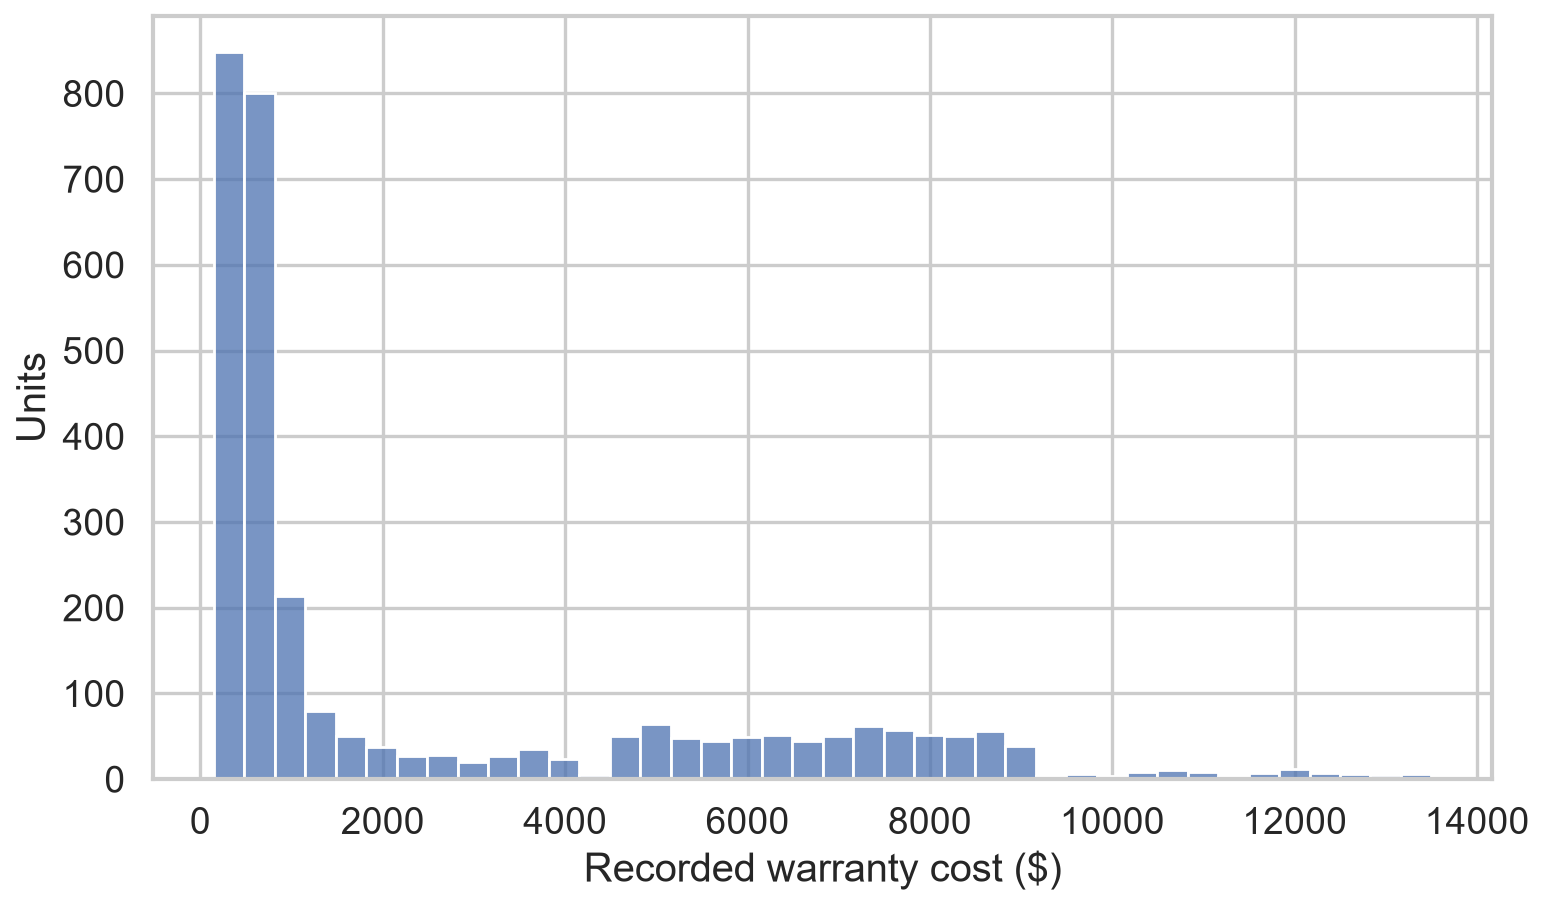

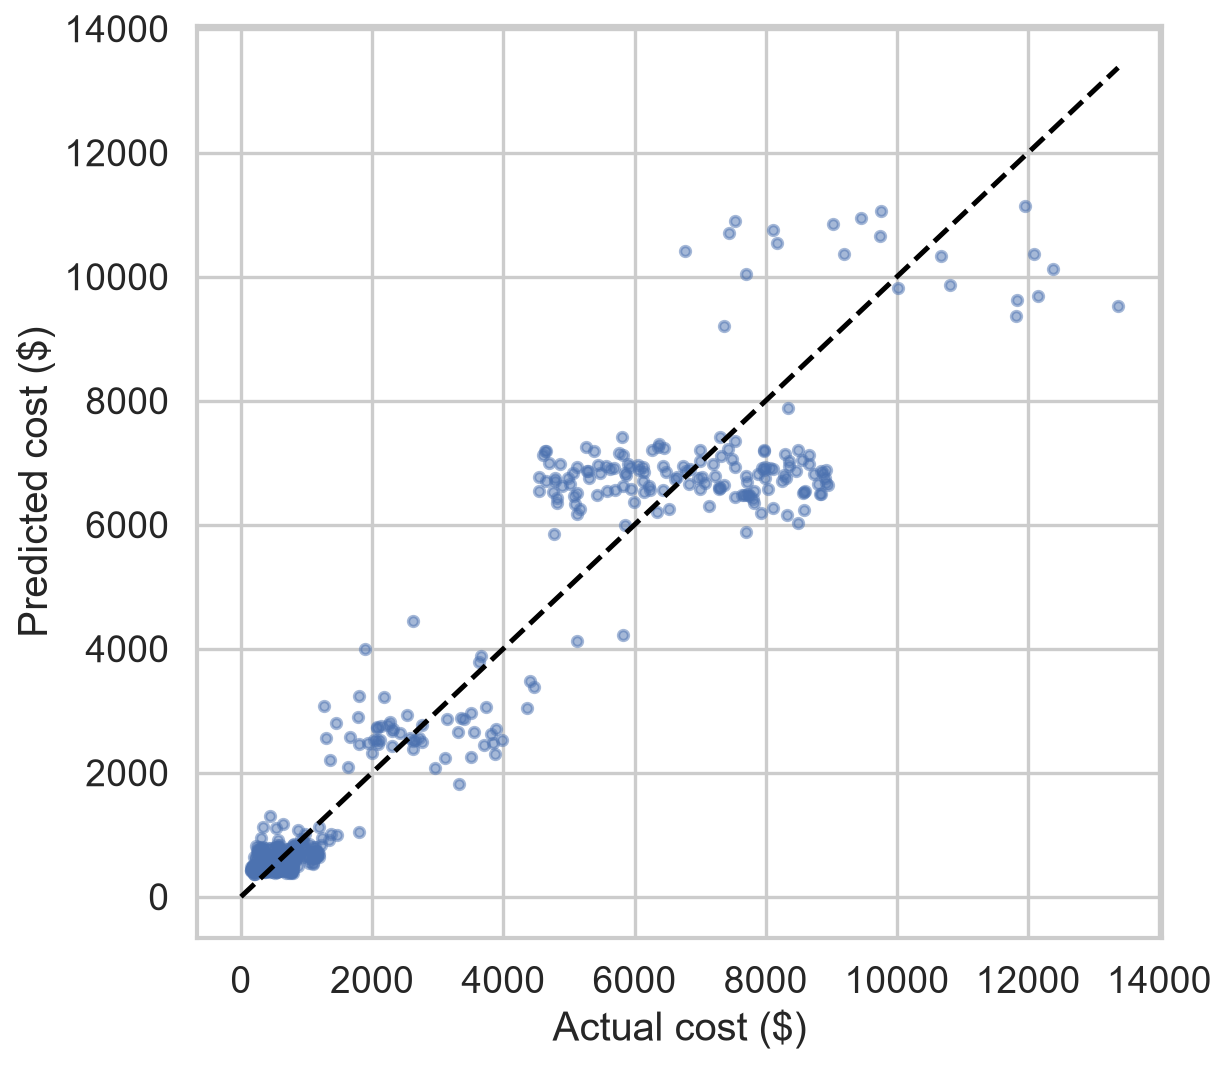

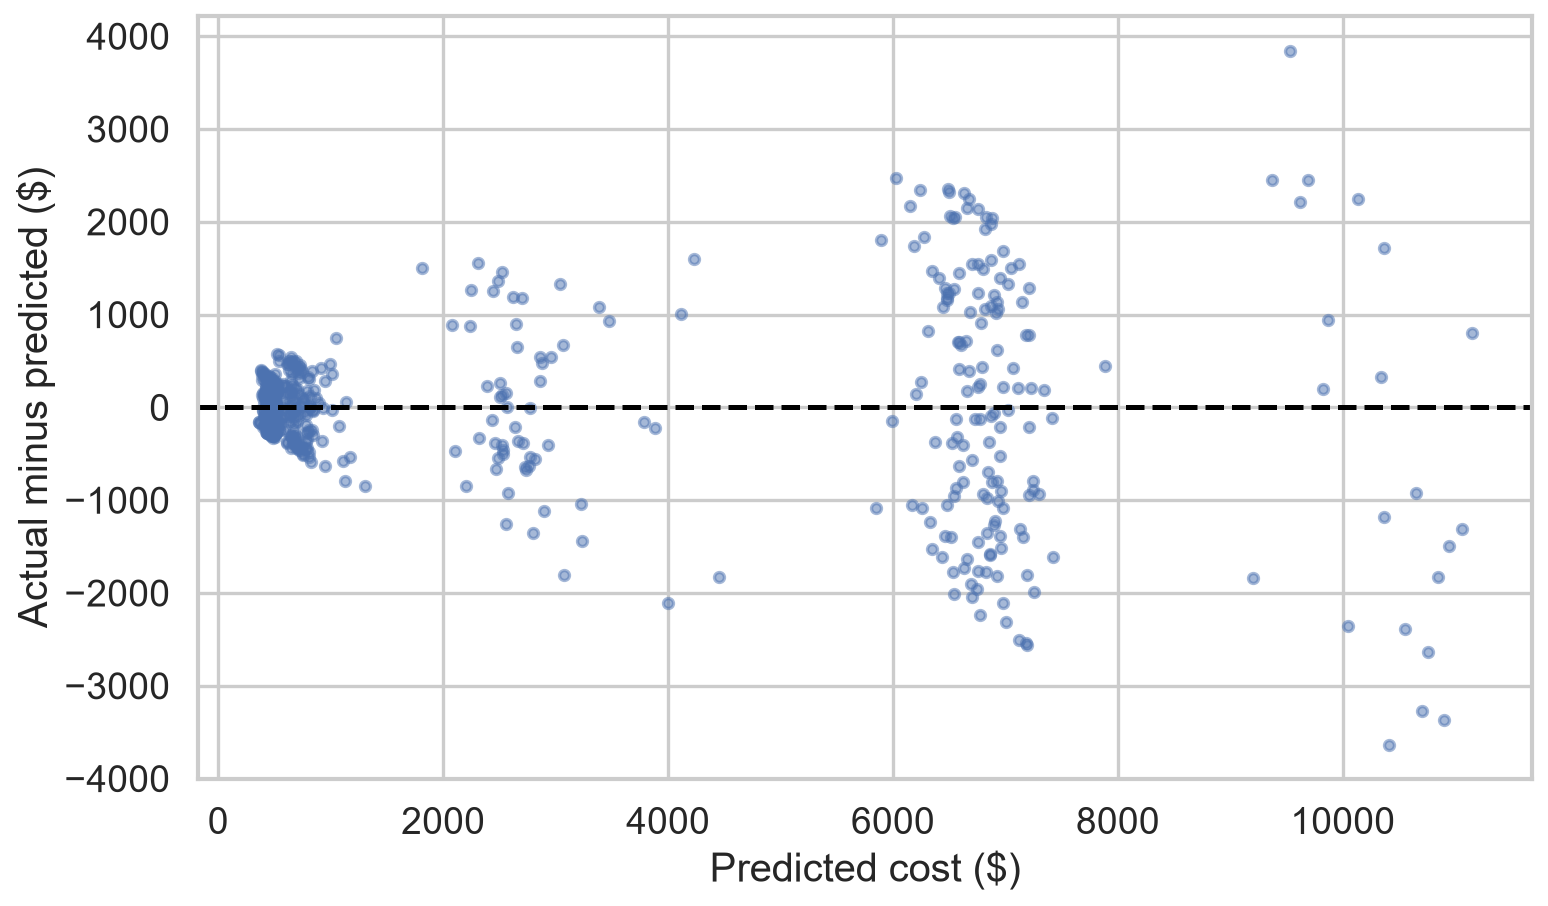

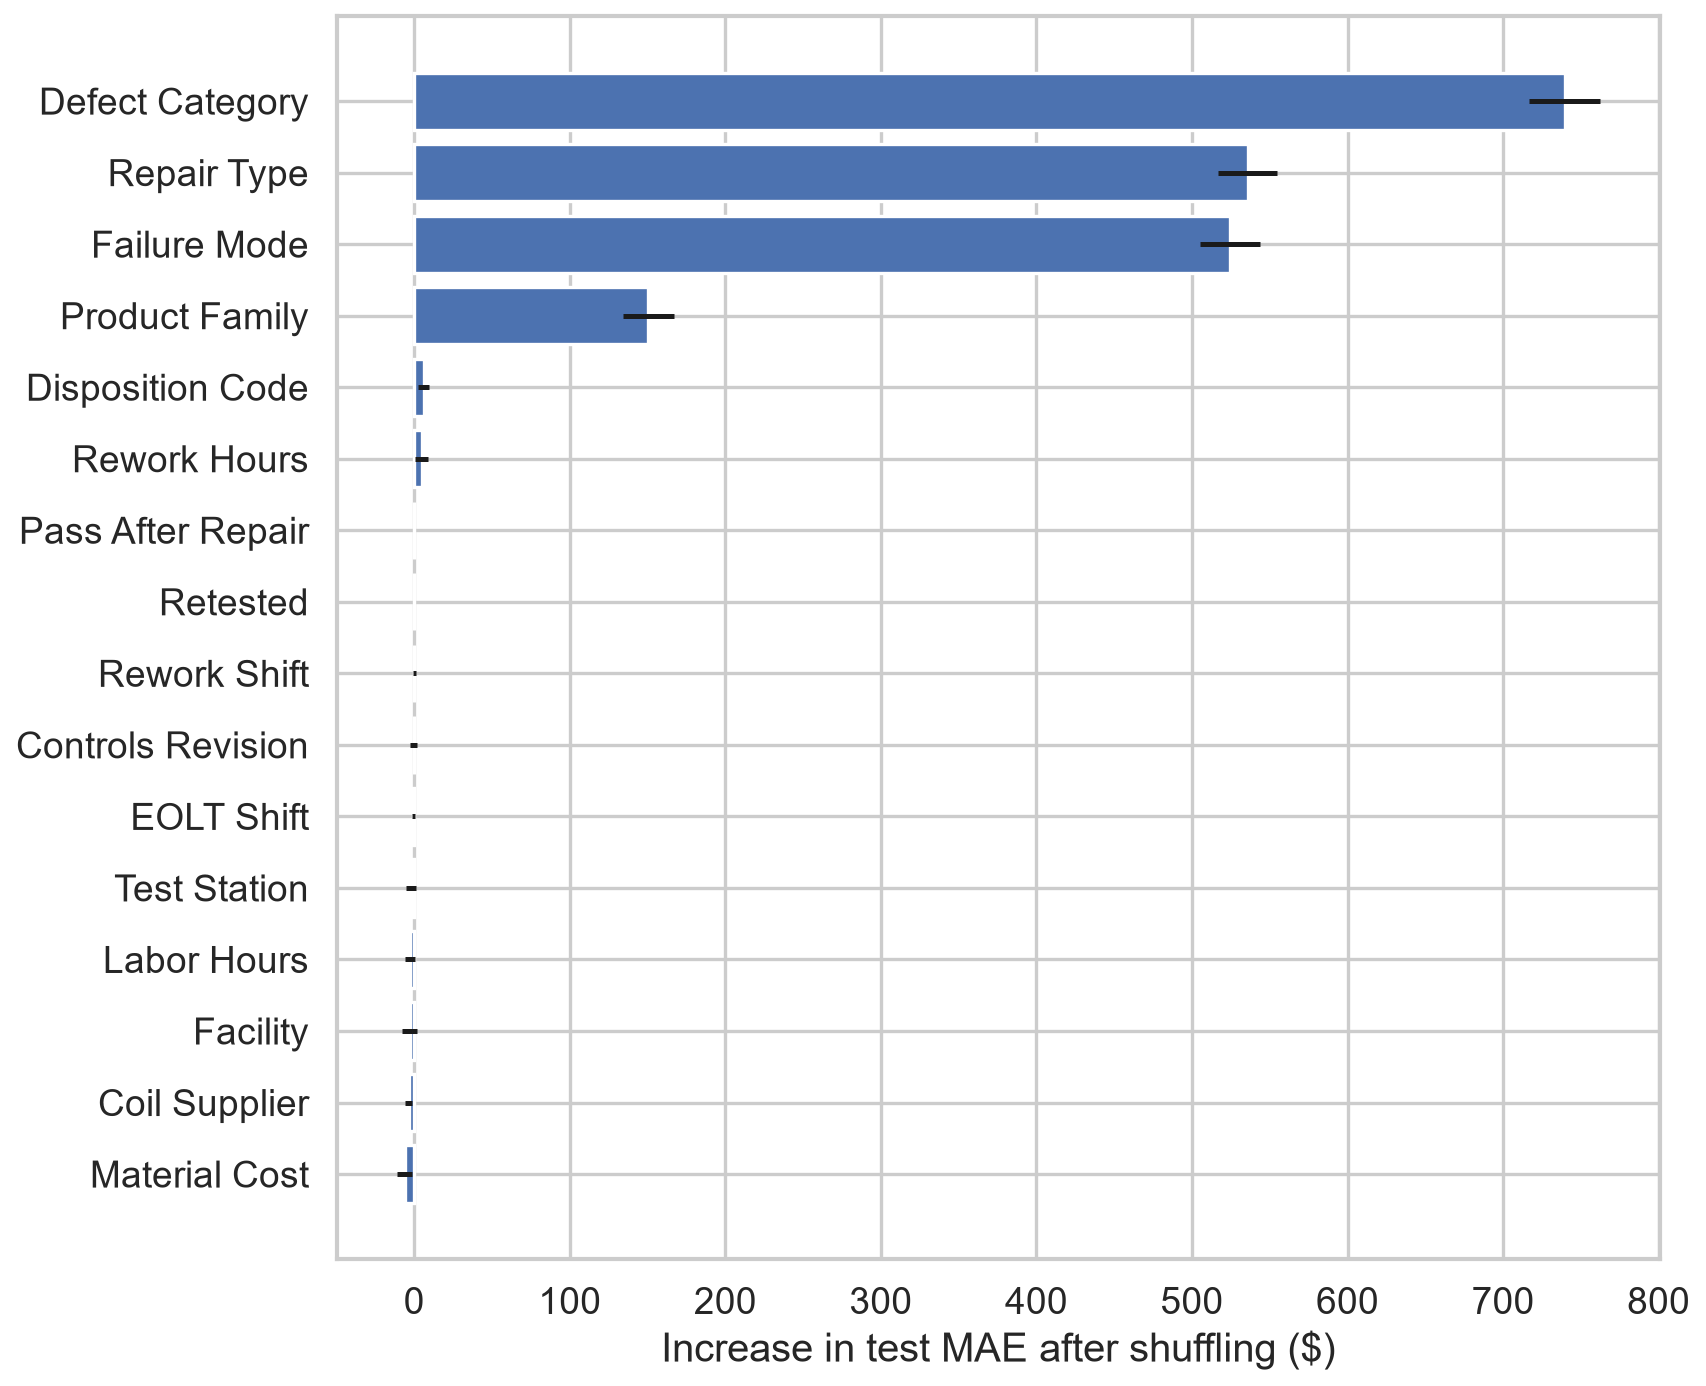

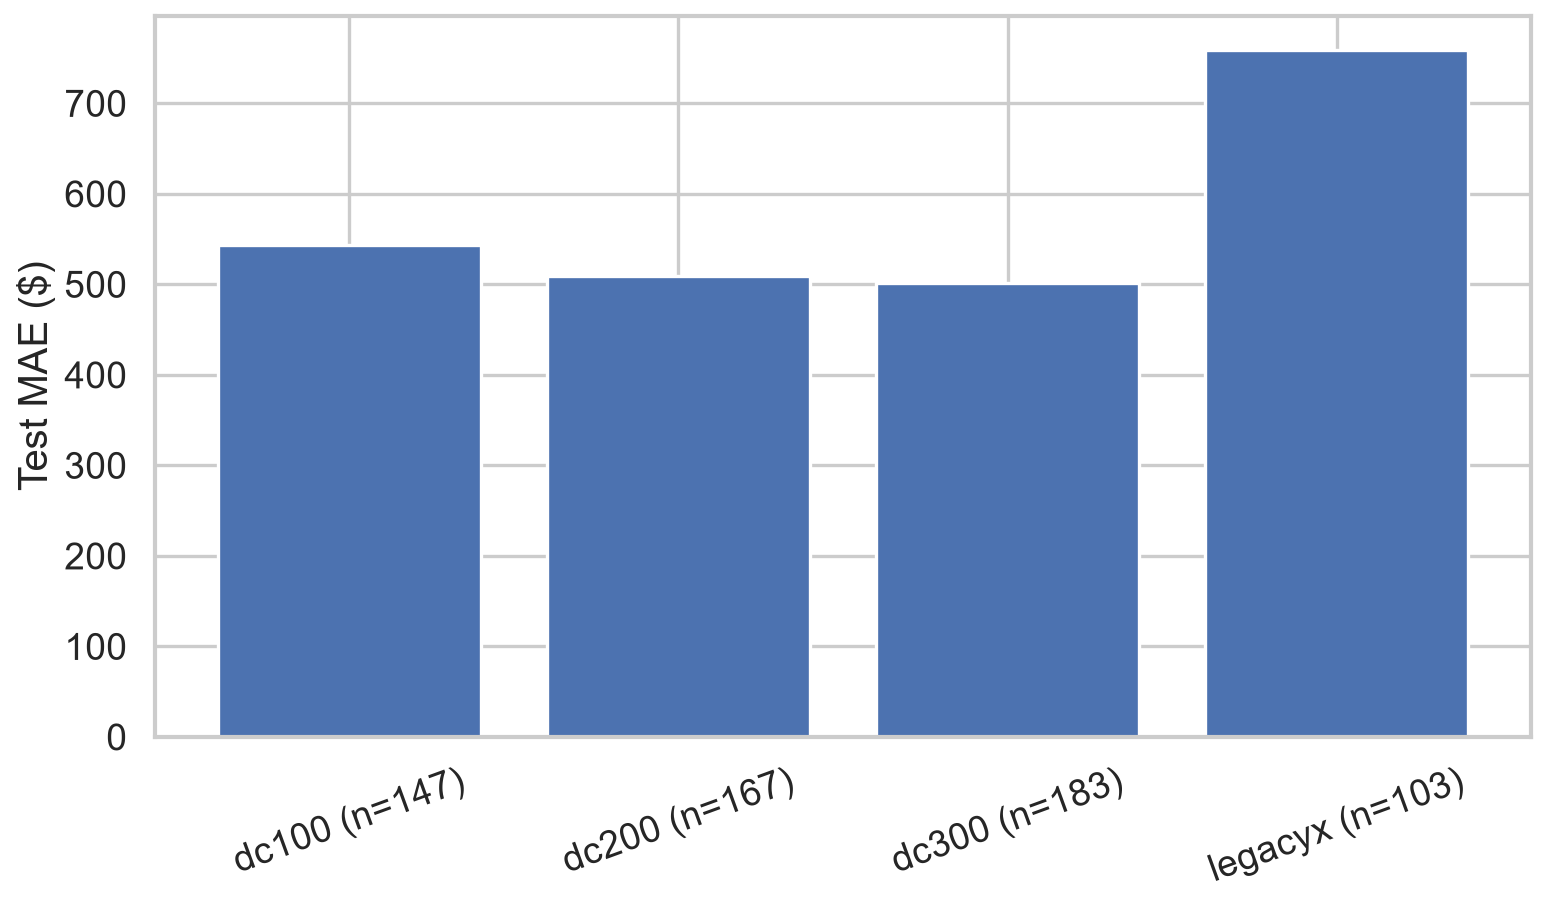

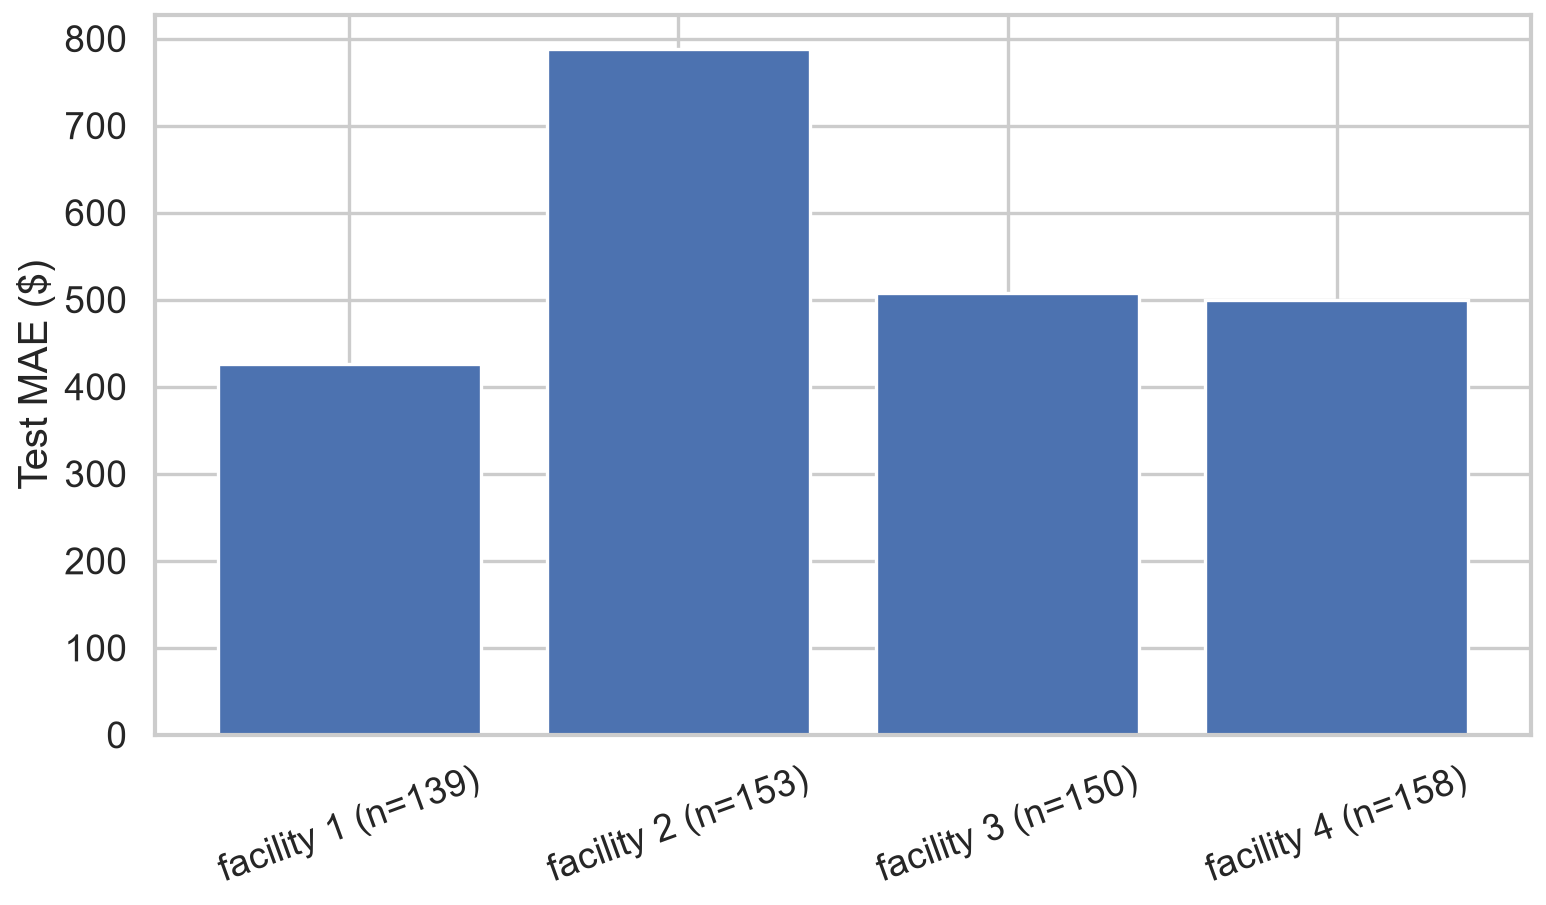

threshold_training_p90          7700.000000
test_units                        64.000000
mean_underprediction_dollars    1249.993505
underpredicted_fraction            0.890625
dtype: float64

In [9]:
for name in ['cost_distribution', 'actual_vs_predicted', 'residuals',
             'permutation_importance', 'error_by_product_family', 'error_by_facility']:
    display(Image(filename=str(OUTPUT_DIR / f'{name}.png')))
display(pd.read_json(OUTPUT_DIR / 'expensive_claims.json', typ='series'))


## 8. Team handoff

Use `modeling_dataset.csv` and `split_assignments.csv` for Linear Regression and XGBoost. `protocol.json` defines the allowed columns and metric. Use `partition()` to recover identical folds and `evaluate_model()` with serial-number-indexed test data. Keep feature scaling specific to the model and fitted only on training folds.

Report all models in the same test metric table. Do not alter models in response to the held-out results. If a new development cycle is needed, establish a fresh evaluation strategy first.

For slides, show the workflow, baseline comparison, actual-versus-predicted plot, expensive-claim behavior, and limitations. Business interventions need separate validation before claiming savings.